# Etapa 6 — Otimização de Estoque: Estratégia para Itens AY

**Projeto:** Planejamento da Cadeia de Suprimentos  
**Foco:** Itens classificados como **AY** na Matriz ABC-XYZ  
**Demanda base:** Previsão gerada por Walk-Forward Validation (`data/previsao_demanda_AY.csv`)  
**Objetivo:** Calcular PP, Estoque de Segurança, EOQ e Cobertura de Estoque para os produtos de maior impacto financeiro, e projetar o impacto da implantação dessas estratégias na taxa de ruptura e nos custos.

---

> **Por que focar em AY?**  
> Os **6 itens AY** concentram **≈ R$ 12,6 MM (~69% do portfólio)** com demanda variável (CV 36–46%).  
> São o ponto de **maior risco financeiro** e **maior retorno da gestão otimizada** em toda a cadeia.


## Carregamento e Preparação


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import norm
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

# ── Bases transacionais e de referência ──────────────────────────────
df           = pd.read_csv('data/base_tratada.csv')
ref_produtos = pd.read_csv('data/ref_produtos.csv')
abc_xyz      = pd.read_csv('data/classificacao_abc_xyz.csv')
previsao     = pd.read_csv('data/previsao_demanda_AY.csv', encoding='utf-8-sig')

df['data_pedido']       = pd.to_datetime(df['data_pedido'])
df['data_entrega_real'] = pd.to_datetime(df['data_entrega_real'])

n_reg  = df.shape[0]
n_prod = df['id_produto'].nunique()
quadrantes = sorted(abc_xyz['classe_abcxyz'].unique())
print(f'Base transacional : {n_reg:,} registros | {n_prod} produtos')
print(f'ABC-XYZ carregado : {len(abc_xyz)} produtos | quadrantes: {quadrantes}')
print(f'Previsao AY carregada: {len(previsao)} produtos')


Base transacional : 4,406 registros | 20 produtos
ABC-XYZ carregado : 20 produtos | quadrantes: ['AY', 'AZ', 'BY', 'BZ', 'CY', 'CZ']
Previsao AY carregada: 6 produtos


## 1. Identificação dos Itens AY

A análise parte diretamente da classificação ABC-XYZ gerada na Etapa 4, filtrando apenas os produtos do quadrante **AY** — combinação de alto valor consumido com demanda moderadamente variável.


In [11]:
# ── Filtrar itens AY a partir da classificação ABC-XYZ ──────────────
itens_ay = (
    abc_xyz[abc_xyz['classe_abcxyz'] == 'AY']
    [['id_produto', 'produto', 'categoria', 'valor_total', 'cv',
      'classe_abc', 'classe_xyz', 'classe_abcxyz']]
    .sort_values('valor_total', ascending=False)
    .reset_index(drop=True)
)

ids_ay = itens_ay['id_produto'].tolist()
df_ay  = df[df['id_produto'].isin(ids_ay)].copy()

valor_ay        = itens_ay['valor_total'].sum()
valor_portfolio = abc_xyz['valor_total'].sum()
pct_ay          = valor_ay / valor_portfolio
n_ay            = len(itens_ay)

print('=' * 60)
print(f'  ITENS AY IDENTIFICADOS: {n_ay} produtos')
print(f'  Valor total AY      : R$ {valor_ay:,.0f}')
print(f'  Valor portfólio     : R$ {valor_portfolio:,.0f}')
print(f'  Concentração AY     : {pct_ay:.1%} do portfólio total')
print('=' * 60)

display(
    itens_ay.assign(
        valor_total=lambda x: x['valor_total'].map('R$ {:,.0f}'.format),
        cv=lambda x: x['cv'].map('{:.1%}'.format)
    )[['produto', 'categoria', 'valor_total', 'cv', 'classe_abcxyz']]
)


  ITENS AY IDENTIFICADOS: 6 produtos
  Valor total AY      : R$ 12,566,740
  Valor portfólio     : R$ 18,158,694
  Concentração AY     : 69.2% do portfólio total


,produto,categoria,valor_total,cv,classe_abcxyz
0,Parafuso,Fixadores,"R$ 4,545,533",36.1%,AY
1,Capacete de Seguranca,EPI,"R$ 2,636,413",36.6%,AY
2,Porca,Fixadores,"R$ 1,798,140",45.5%,AY
3,Oculos de Protecao,EPI,"R$ 1,429,249",42.9%,AY
4,Luva de Seguranca,EPI,"R$ 1,235,319",37.9%,AY
5,Arruela,Fixadores,"R$ 922,086",43.1%,AY


## 2. Previsão de Demanda — Base para os Cálculos

A demanda média utilizada nos cálculos de ES, PP e EOQ **não é histórica** — é a previsão gerada pelo notebook `05_previsao_demanda.ipynb`, via Walk-Forward Validation com seleção automática do melhor modelo por produto.

| Parâmetro | Origem |
|---|---|
| **Demanda média** | Previsão Jan-Mar/2025 (média dos 3 meses) |
| **Desvio-padrão da demanda** | Série histórica (variabilidade real observada) |
| **Lead time** | Dados históricos de `base_tratada.csv` |
| **Preço unitário** | Média histórica de `preco_unitario` por produto (`base_tratada.csv`) |


In [12]:
# ── Exibir previsão utilizada ─────────────────────────────────────────
cols_prev = ['produto', 'modelo_usado', 'mape_pct', 'mae',
             'prev_2025_01', 'prev_2025_02', 'prev_2025_03', 'prev_total_3m']

display(
    previsao[cols_prev].rename(columns={
        'produto':      'Produto',
        'modelo_usado': 'Modelo',
        'mape_pct':     'MAPE (%)',
        'mae':          'MAE (un)',
        'prev_2025_01': 'Jan/2025',
        'prev_2025_02': 'Fev/2025',
        'prev_2025_03': 'Mar/2025',
        'prev_total_3m':'Total 3m',
    }).assign(**{
        'Jan/2025':  lambda x: x['Jan/2025'].map('{:,.0f}'.format),
        'Fev/2025':  lambda x: x['Fev/2025'].map('{:,.0f}'.format),
        'Mar/2025':  lambda x: x['Mar/2025'].map('{:,.0f}'.format),
        'Total 3m':  lambda x: x['Total 3m'].map('{:,.0f}'.format),
        'MAPE (%)':  lambda x: x['MAPE (%)'].map('{:.1f}%'.format),
        'MAE (un)':  lambda x: x['MAE (un)'].map('{:,.0f}'.format),
    })
)


,Produto,Modelo,MAPE (%),MAE (un),Jan/2025,Fev/2025,Mar/2025,Total 3m
0,Parafuso,SARIMA,29.9%,"7,372","31,132","39,260","36,351","106,743"
1,Capacete de Seguranca,SARIMA,49.6%,613,"3,936","2,516","3,080","9,532"
2,Porca,XGBoost,29.0%,"7,106","31,802","30,363","32,039","94,204"
3,Oculos de Protecao,Holt-Winters,38.7%,968,"3,230","2,030","3,502","8,762"
4,Luva de Seguranca,Holt-Winters,29.3%,822,"2,114","2,511","3,421","8,046"
5,Arruela,SARIMA,23.6%,"5,668","23,545","50,050","15,885","89,480"


## 3. Parâmetros Base dos Itens AY


In [13]:
# ── Demanda prevista (media mensal dos 3 meses) ──────────────────────
dem_prev = previsao[['id_produto', 'prev_2025_01', 'prev_2025_02',
                      'prev_2025_03', 'prev_total_3m']].copy()
dem_prev['demanda_media_mensal'] = (
    dem_prev[['prev_2025_01', 'prev_2025_02', 'prev_2025_03']].mean(axis=1)
)
dem_prev['demanda_media_diaria'] = dem_prev['demanda_media_mensal'] / 30
dem_prev['demanda_anual_prev']   = dem_prev['prev_total_3m'] * 4

# ── Desvio-padrao da demanda (historico) ─────────────────────────────
dem_hist = (
    df_ay.groupby(['id_produto'])['quantidade_pedida']
    .apply(lambda x: x.groupby([df_ay.loc[x.index, 'ano'],
                                 df_ay.loc[x.index, 'mes']]).sum().std())
    .reset_index(name='demanda_std_mensal')
)
dem_hist['demanda_std_mensal'] = dem_hist['demanda_std_mensal'].fillna(0)
dem_hist['demanda_std_diaria'] = dem_hist['demanda_std_mensal'] / np.sqrt(30)

# ── Parametros de Lead Time (historico) ─────────────────────────────
params_lt = (
    df_ay.groupby('id_produto')['lead_time_real']
    .agg(['mean', 'std']).reset_index()
    .rename(columns={'mean': 'lead_time_medio', 'std': 'lead_time_std'})
)
params_lt['lead_time_std'] = params_lt['lead_time_std'].fillna(0)

# ── Estoque e Giro Atual ─────────────────────────────────────────────
estoque_atual = (
    df_ay.sort_values('data_pedido').groupby('id_produto').last()
    [['estoque_disponivel', 'estoque_minimo', 'estoque_maximo']].reset_index()
)
giro_map = df_ay.groupby('id_produto')['giro_produto'].first().reset_index()

# ── Preco unitario base (media historica dos pedidos) ────────────────
preco_base = (
    df_ay.groupby('id_produto')['preco_unitario'].mean()
    .reset_index(name='preco_unitario_base')
)

# ── Consolidar parametros base ───────────────────────────────────────
params = (
    dem_prev[['id_produto', 'demanda_media_mensal', 'demanda_media_diaria',
              'demanda_anual_prev']]
    .merge(dem_hist[['id_produto', 'demanda_std_diaria']], on='id_produto')
    .merge(params_lt,    on='id_produto')
    .merge(estoque_atual, on='id_produto')
    .merge(giro_map,      on='id_produto')
    .merge(preco_base,    on='id_produto', how='left')
    .merge(itens_ay[['id_produto', 'produto', 'categoria',
                      'valor_total', 'cv', 'classe_abcxyz']], on='id_produto')
)

print('Parametros base — previsao como demanda de referencia:')
display(
    params[['produto', 'giro_produto', 'demanda_media_diaria', 'demanda_std_diaria',
            'lead_time_medio', 'lead_time_std', 'preco_unitario_base']]
    .round(2)
)


Parametros base — previsao como demanda de referencia:


,produto,giro_produto,demanda_media_diaria,demanda_std_diaria,lead_time_medio,lead_time_std,preco_unitario_base
0,Parafuso,alto,1186.03,1722.37,14.04,13.98,4.84
1,Capacete de Seguranca,alto,105.91,162.07,13.26,13.91,30.12
2,Porca,alto,1046.71,2171.89,13.00,13.52,1.91
3,Oculos de Protecao,alto,97.36,192.93,13.51,13.83,16.12
4,Luva de Seguranca,alto,89.40,181.05,14.42,14.86,13.09
5,Arruela,alto,994.22,2076.86,7.48,4.73,0.97


### Parâmetros Base — 6 Itens AY

| Produto | Giro | Demanda Prev./dia | Desvio Hist./dia | Lead Time Médio | Lead Time Std | Preço Unit. |
|---|:---:|:---:|:---:|:---:|:---:|:---:|
| Parafuso | Alto | 1.186 | 1.722 | 14,04 dias | 13,98 | R$ 4,84 |
| Capacete de Segurança | Alto | 106 | 162 | 13,26 dias | 13,91 | R$ 30,12 |
| Porca | Alto | 1.047 | 2.172 | 13,00 dias | 13,52 | R$ 1,91 |
| Óculos de Proteção | Alto | 97 | 193 | 13,51 dias | 13,83 | R$ 16,12 |
| Luva de Segurança | Alto | 89 | 181 | 14,42 dias | 14,86 | R$ 13,09 |
| Arruela | Alto | 994 | 2.077 | 7,48 dias | 4,73 | R$ 0,97 |

> **Nota metodológica:** A demanda diária é a **média das previsões Jan-Mar/2025 ÷ 30**.
> O desvio-padrão continua sendo extraído da série **histórica** (2022-2024),
> pois representa a variabilidade real observada — não alterada pelo modelo de previsão.

> **Ponto de atenção:** em 5 dos 6 itens o desvio-padrão do lead time é praticamente igual
> ao lead time médio (~13–15 dias). Isso reflete a mistura de fornecedores nacionais (~5 dias)
> e internacionais (~33 dias) no mesmo produto, e é o que mais pesa no cálculo do Estoque de Segurança.

## 4. Política de Gestão para Itens AY

Os itens AY combinam dois fatores de risco simultâneos:

| Fator | Detalhe | Implicação |
|---|---|---|
| **Classe A** | ~69% do valor financeiro do portfólio | Ruptura = impacto direto no resultado |
| **Classe Y** | CV entre 20–50% (demanda variável) | Risco de desabastecimento por picos de demanda |

### Parâmetros da Política AY

| Parâmetro | Valor | Justificativa |
|---|---|---|
| Nível de Serviço | **98%** | Alto valor exige garantia robusta de disponibilidade |
| Fator Z | **2,054** | Correspondente ao NS 98% (distribuição normal padrão) |
| Taxa de posse (I) | **20% a.a.** | Custo de oportunidade + armazenagem |
| Custo de emissão (S) | **R$ 50** | Custo de processamento por pedido emitido |


## 5. Cobertura de Estoque

$$Cobertura = \dfrac{Estoque\ Disponível}{D_{média\ diária\ prevista}}$$

Indica **quantos dias de demanda** o estoque atual consegue cobrir, usando a demanda prevista como referência.


In [14]:
# Parametros de politica antecipados (necessario para cobertura recomendada)
NS_AY = 0.98
Z_AY  = norm.ppf(NS_AY)
I     = 0.20
S     = 50

def calc_es(row, z):
    return z * np.sqrt(
        row['lead_time_medio'] * row['demanda_std_diaria'] ** 2
        + row['demanda_media_diaria'] ** 2 * row['lead_time_std'] ** 2
    )

params['es_ns98'] = params.apply(lambda r: calc_es(r, Z_AY), axis=1).round(0)
params['es_sugerido']    = params['es_ns98']
params['custo_manut_es'] = (params['es_sugerido'] * params['preco_unitario_base'] * I).round(0)

params['pp_otimizado'] = (
    params['demanda_media_diaria'] * params['lead_time_medio'] + params['es_ns98']
).round(0)

# Cobertura atual (dias)
params['cobertura_atual_dias'] = (
    params['estoque_disponivel'] / params['demanda_media_diaria'].replace(0, np.nan)
).clip(upper=365).fillna(0).round(1)

display(
    params[['produto', 'estoque_disponivel', 'demanda_media_diaria', 'cobertura_atual_dias']]
    .rename(columns={
        'produto':              'Produto',
        'estoque_disponivel':   'Estoque Atual (un)',
        'demanda_media_diaria': 'Demanda Prev. Dia (un)',
        'cobertura_atual_dias': 'Cobertura Atual (dias)',
    })
    .round({'Demanda Prev. Dia (un)': 1})
    .reset_index(drop=True)
)


,Produto,Estoque Atual (un),Demanda Prev. Dia (un),Cobertura Atual (dias)
0,Parafuso,718998,1186.0,365.0
1,Capacete de Seguranca,66289,105.9,365.0
2,Porca,728263,1046.7,365.0
3,Oculos de Protecao,66901,97.4,365.0
4,Luva de Seguranca,72224,89.4,365.0
5,Arruela,722922,994.2,365.0


### Estoque Atual vs. Cobertura Real

> **Situação de excesso, não de falta:** com a demanda prevista, todos os 6 itens AY têm cobertura
> no teto de **365 dias** (sem o teto, o estoque atual cobriria de ~600 a ~800 dias de demanda).
> A cobertura recomendada com NS 98% (lead time + ES) fica entre 23 e 49 dias — ou seja,
> não há urgência de reposição em nenhum produto.
>
> **Ressalva sobre o dado:** o `estoque_disponivel` do último registro de cada item
> (66 mil a 728 mil un.) está muito acima do `estoque_maximo` cadastrado (2.000 a 20.000 un.).
> Vale validar essa informação na origem antes de usá-la para decisões de compra.

## 6. Estoque de Segurança (ES)

$$ES = Z \times \sqrt{LT \times \sigma_D^2 + D^2 \times \sigma_{LT}^2}$$

Onde:
- $Z = 2{,}054$ → Nível de serviço **98%** (política AY)
- $LT$ = lead time médio (dias)
- $\sigma_D$ = desvio padrão da demanda diária (histórico)
- $D$ = demanda média diária (**previsão**)
- $\sigma_{LT}$ = desvio padrão do lead time

A fórmula captura **dois vetores de incerteza** ao mesmo tempo:
- $LT \times \sigma_D^2$ → risco da demanda variar durante o prazo de entrega
- $D^2 \times \sigma_{LT}^2$ → risco do fornecedor atrasar com demanda constante


Z por nivel de servico:
  NS 90%                         Z=1.282  ES total=  58,876 un  Custo/ano=R$     55,348
  NS 95%                         Z=1.645  ES total=  75,567 un  Custo/ano=R$     71,041
  NS 98% (politica AY)           Z=2.054  ES total=  94,352 un  Custo/ano=R$     88,701


,Produto,NS 90%,NS 95%,NS 98% (politica AY)
0,Parafuso,22798.0,29261.0,36535.0
1,Capacete de Seguranca,2034.0,2611.0,3260.0
2,Porca,20726.0,26601.0,33214.0
3,Oculos de Protecao,1950.0,2503.0,3125.0
4,Luva de Seguranca,1917.0,2460.0,3072.0
5,Arruela,9451.0,12131.0,15146.0


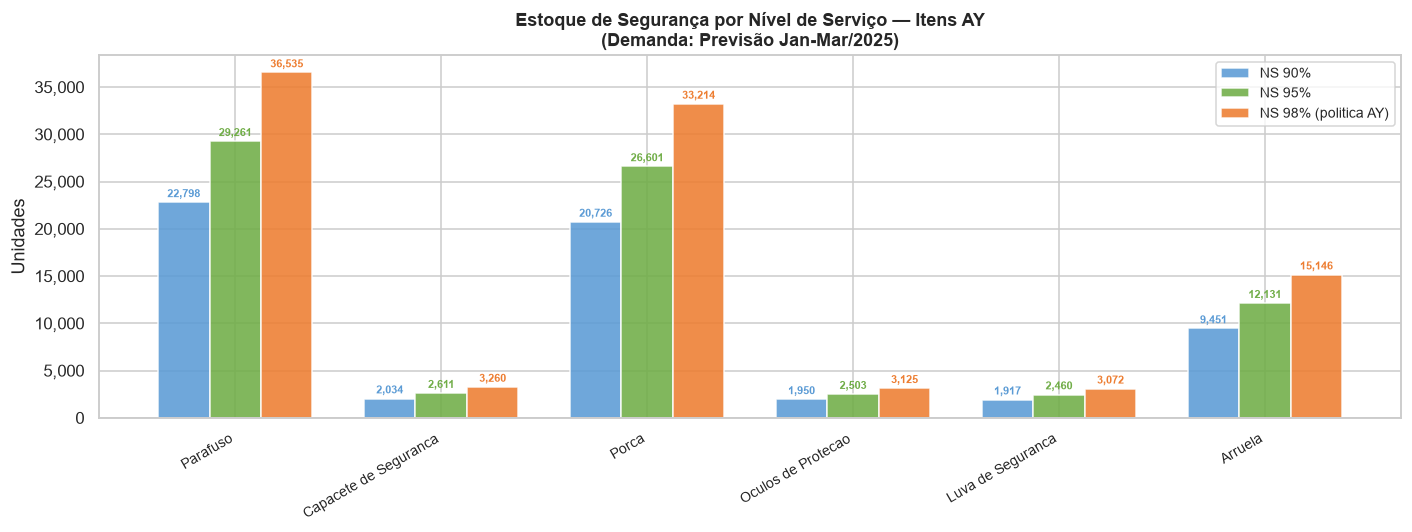

Cobertura proporcionada pelo ES — por Nivel de Servico:


,Produto,Demanda Prev./dia,Desvio Hist./dia,Cobertura ES NS 90% (dias),Cobertura ES NS 95% (dias),Cobertura ES NS 98% (politica AY) (dias)
0,Parafuso,1186.0,1722.4,19.2,24.7,30.8
1,Capacete de Seguranca,105.9,162.1,19.2,24.7,30.8
2,Porca,1046.7,2171.9,19.8,25.4,31.7
3,Oculos de Protecao,97.4,192.9,20.0,25.7,32.1
4,Luva de Seguranca,89.4,181.0,21.4,27.5,34.4
5,Arruela,994.2,2076.9,9.5,12.2,15.2


In [15]:
# ── ES para os 3 niveis de servico ───────────────────────────────────
niveis = [
    {'ns': 0.90, 'label': 'NS 90%',               'cor': '#5b9bd5'},
    {'ns': 0.95, 'label': 'NS 95%',               'cor': '#70ad47'},
    {'ns': 0.98, 'label': 'NS 98% (politica AY)', 'cor': '#ed7d31'},
]
for n in niveis:
    z = norm.ppf(n['ns'])
    col = f'es_ns{int(n["ns"]*100)}'
    n['col'] = col
    n['z']   = z
    params[col] = params.apply(lambda r: calc_es(r, z), axis=1).round(0)

params['es_sugerido']    = params['es_ns98']
params['custo_manut_es'] = (params['es_sugerido'] * params['preco_unitario_base'] * I).round(0)

# Resumo por nivel de servico
print('Z por nivel de servico:')
for n in niveis:
    total = params[n['col']].sum()
    custo = (params[n['col']] * params['preco_unitario_base'] * I).sum()
    print(f"  {n['label']:30s} Z={n['z']:.3f}  "
          f"ES total={total:>8,.0f} un  Custo/ano=R$ {custo:>10,.0f}")

tabela = params[['produto'] + [n['col'] for n in niveis]].copy()
tabela.columns = ['Produto'] + [n['label'] for n in niveis]
display(tabela.round(0))

# Grafico comparativo: ES por NS
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(params))
w = 0.25
labels_prod = [p[:22] for p in params['produto']]
offsets = [-w, 0, w]

for n, offset in zip(niveis, offsets):
    bars = ax.bar(x + offset, params[n['col']], w,
                  label=n['label'], color=n['cor'], alpha=0.88)
    for bar, v in zip(bars, params[n['col']]):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + params['es_ns98'].max() * 0.008,
                f'{v:,.0f}', ha='center', va='bottom', fontsize=7.5,
                fontweight='bold', color=n['cor'])

ax.set_xticks(x)
ax.set_xticklabels(labels_prod, rotation=30, ha='right', fontsize=9)
ax.set_title('Estoque de Segurança por Nível de Serviço — Itens AY\n'
             '(Demanda: Previsão Jan-Mar/2025)', fontsize=12, fontweight='bold')
ax.set_ylabel('Unidades')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# Cobertura em dias que cada ES comporta
for n in niveis:
    col_cob = f'cobertura_es_{n["col"]}'
    params[col_cob] = (
        params[n['col']] / params['demanda_media_diaria'].replace(0, np.nan)
    ).round(1)
    n['col_cob'] = col_cob

tabela_cob = params[
    ['produto', 'demanda_media_diaria', 'demanda_std_diaria']
    + [n['col_cob'] for n in niveis]
].copy()
tabela_cob.columns = (
    ['Produto', 'Demanda Prev./dia', 'Desvio Hist./dia']
    + [f'Cobertura ES {n["label"]} (dias)' for n in niveis]
)
print('Cobertura proporcionada pelo ES — por Nivel de Servico:')
display(tabela_cob.round({'Demanda Prev./dia': 1, 'Desvio Hist./dia': 1}).reset_index(drop=True))


### Custo Anual de Manutenção do Estoque de Segurança

$$C_{manut} = ES \times P \times I$$

| Variável | Significado | Valor Usado |
|:---:|---|---|
| $ES$ | Estoque de Segurança (unidades) | Calculado por produto |
| $P$ | Preço unitário do produto (R$/un) | Média histórica de `preco_unitario` |
| $I$ | Taxa de posse anual | 20% a.a. |


## 7. Ponto de Pedido (PP)

$$PP = D_{prevista} \times LT_{médio} + ES$$

O PP indica o nível de estoque que **dispara o reabastecimento**, garantindo que o estoque não chegue a zero durante o lead time de entrega.

**Comparativo:**
- **PP Atual** = `estoque_minimo` (parâmetro fixado manualmente no sistema)
- **PP Otimizado** = demanda prevista × lead time real + ES com NS 98%


Itens com PP subestimado: 6/6 (100%)
Gap medio (PP otimizado - PP atual): 19,375 unidades



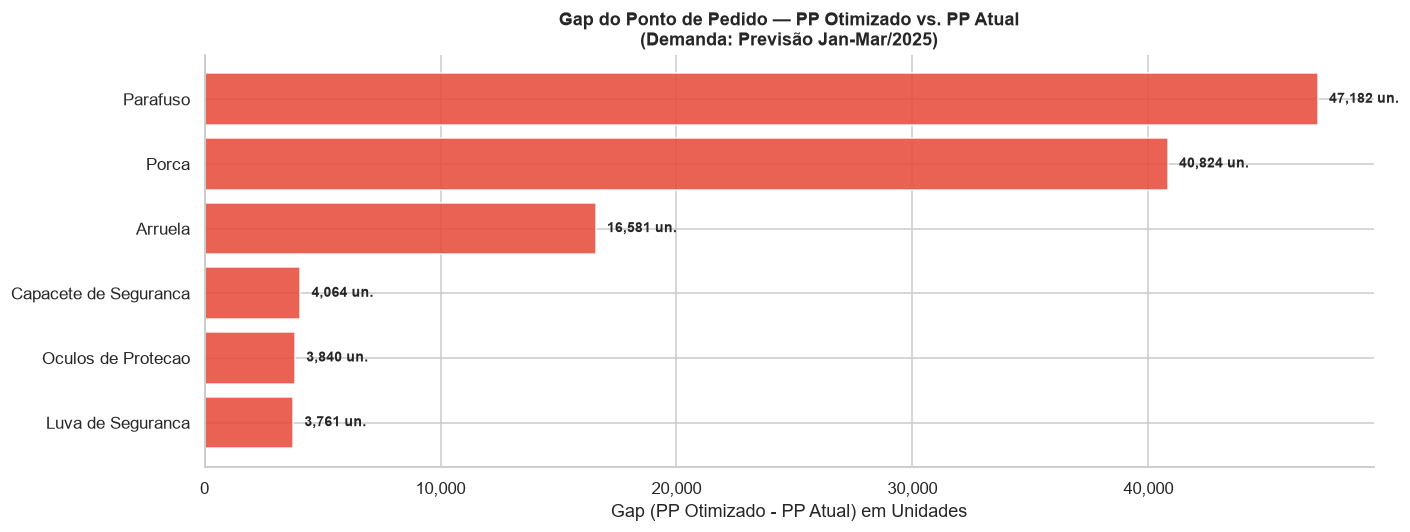

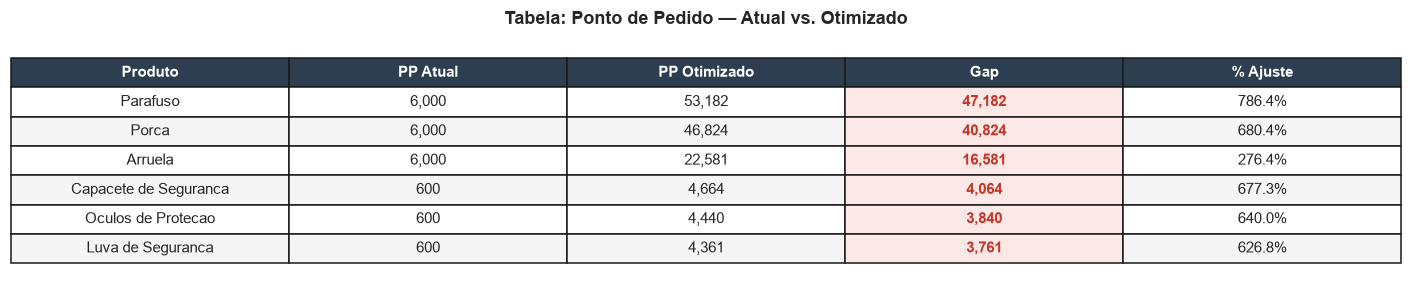

In [16]:
params['pp_atual']     = params['estoque_minimo']
params['pp_otimizado'] = (
    params['demanda_media_diaria'] * params['lead_time_medio'] + params['es_sugerido']
).round(0)
params['gap_pp']     = params['pp_otimizado'] - params['pp_atual']
params['pct_ajuste'] = (params['gap_pp'] / params['pp_atual'] * 100).round(1)

n_sub   = (params['gap_pp'] > 0).sum()
gap_med = params['gap_pp'].mean()
print(f'Itens com PP subestimado: {n_sub}/{len(params)} ({n_sub/len(params):.0%})')
print(f'Gap medio (PP otimizado - PP atual): {gap_med:,.0f} unidades\n')

# Grafico 1: Barras horizontais do Gap
pp_gap_sorted = params[['produto', 'gap_pp']].sort_values('gap_pp', ascending=True).copy()
labels_sorted = [p[:24] for p in pp_gap_sorted['produto']]

fig1, ax1 = plt.subplots(figsize=(13, 5))
cores_gap = ['#e74c3c' if v > 0 else '#2ecc71' for v in pp_gap_sorted['gap_pp']]
bars = ax1.barh(labels_sorted, pp_gap_sorted['gap_pp'], color=cores_gap, alpha=0.88)

for bar, v in zip(bars, pp_gap_sorted['gap_pp']):
    offset = pp_gap_sorted['gap_pp'].max() * 0.01
    ha = 'left' if v >= 0 else 'right'
    x_pos = v + offset if v >= 0 else v - offset
    ax1.text(x_pos, bar.get_y() + bar.get_height() / 2,
             f'{v:,.0f} un.', va='center', ha=ha, fontsize=9, fontweight='bold')

ax1.axvline(0, color='gray', linewidth=1, linestyle='--')
ax1.set_xlabel('Gap (PP Otimizado - PP Atual) em Unidades')
ax1.set_title('Gap do Ponto de Pedido — PP Otimizado vs. PP Atual\n'
              '(Demanda: Previsão Jan-Mar/2025)', fontsize=12, fontweight='bold')
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
sns.despine(left=False, bottom=False)
plt.tight_layout()
plt.show()

# Grafico 2: Tabela PP Atual, PP Otimizado, Gap, % Ajuste
tabela_pp = (
    params[['produto', 'pp_atual', 'pp_otimizado', 'gap_pp', 'pct_ajuste']]
    .sort_values('gap_pp', ascending=False)
    .reset_index(drop=True)
    .rename(columns={
        'produto':      'Produto',
        'pp_atual':     'PP Atual',
        'pp_otimizado': 'PP Otimizado',
        'gap_pp':       'Gap',
        'pct_ajuste':   '% Ajuste',
    })
)

col_labels = list(tabela_pp.columns)
cell_text  = []
for _, row in tabela_pp.iterrows():
    cell_text.append([
        row['Produto'],
        f"{row['PP Atual']:,.0f}",
        f"{row['PP Otimizado']:,.0f}",
        f"{row['Gap']:,.0f}",
        f"{row['% Ajuste']:.1f}%",
    ])

fig2, ax2 = plt.subplots(figsize=(13, 2.8))
ax2.axis('off')
table = ax2.table(cellText=cell_text, colLabels=col_labels,
                  cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)
for j in range(len(col_labels)):
    table[0, j].set_facecolor('#2c3e50')
    table[0, j].set_text_props(color='white', fontweight='bold')
for i in range(1, len(cell_text) + 1):
    gap_val = tabela_pp.iloc[i - 1]['Gap']
    for j in range(len(col_labels)):
        if j == 3:
            table[i, j].set_facecolor('#fde8e8' if gap_val > 0 else '#e8fde8')
            table[i, j].set_text_props(
                color='#c0392b' if gap_val > 0 else '#27ae60', fontweight='bold')
        else:
            table[i, j].set_facecolor('#f5f5f5' if i % 2 == 0 else 'white')
ax2.set_title('Tabela: Ponto de Pedido — Atual vs. Otimizado',
              fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 8. Lote Econômico de Compra (EOQ)

$$EOQ = \sqrt{\dfrac{2 \times D_{anual\ prevista} \times S}{H}}$$

Onde:
- $D_{anual\ prevista}$ = previsão 3 meses × 4 (demanda anual estimada)
- $S$ = custo de emissão por pedido = **R$ 50**
- $H$ = custo de manutenção unitário/ano = preço unitário × **20%**

O EOQ minimiza o **custo total de estoque** (soma dos custos de pedido e de manutenção).


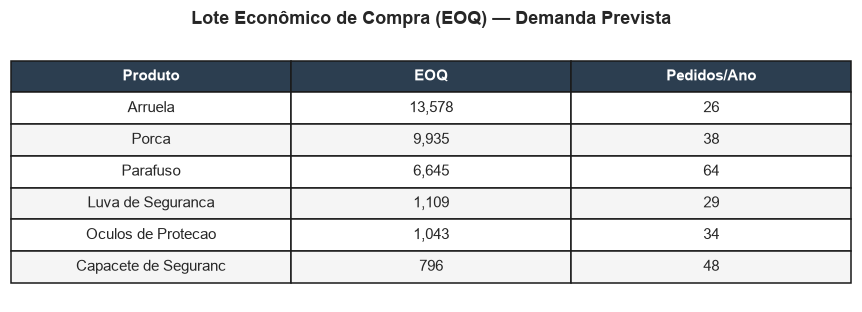

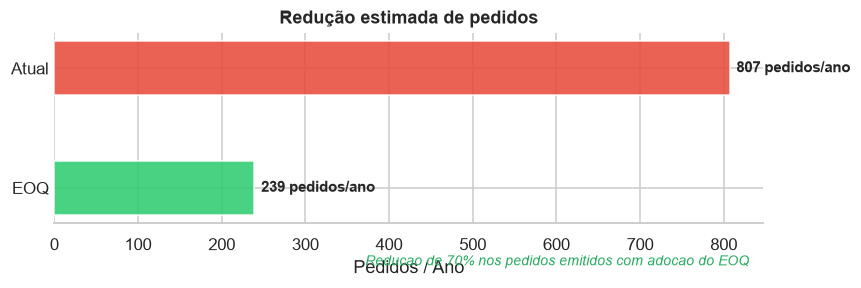


Resumo EOQ:
  Total pedidos/ano ATUAL : 807
  Total pedidos/ano EOQ   : 239
  Reducao estimada        : 70%


In [17]:
params['custo_posse'] = params['preco_unitario_base'] * I

params['eoq'] = np.sqrt(
    (2 * params['demanda_anual_prev'] * S)
    / params['custo_posse'].replace(0, np.nan)
).round(0).fillna(0)

params['pedidos_por_ano_eoq'] = (
    params['demanda_anual_prev'] / params['eoq'].replace(0, np.nan)
).round(0)

params['custo_total_eoq'] = (
    (params['demanda_anual_prev'] / params['eoq'].replace(0, np.nan)) * S
    + (params['eoq'] / 2) * params['custo_posse']
).round(0)

# Pedidos/ano pela politica atual (lote medio real por produto)
lote_atual = (
    df_ay.groupby('id_produto')['quantidade_pedida']
    .mean().round(0).reset_index()
    .rename(columns={'quantidade_pedida': 'lote_atual_medio'})
)
params = params.merge(lote_atual, on='id_produto', how='left')
params['pedidos_por_ano_atual'] = (
    params['demanda_anual_prev'] / params['lote_atual_medio'].replace(0, np.nan)
).round(0)

# Tabela EOQ
tabela_eoq = (
    params[['produto', 'eoq', 'pedidos_por_ano_eoq']]
    .sort_values('eoq', ascending=False)
    .reset_index(drop=True)
)
nomes_curtos = {
    'Protetor Auricular':         'Protetor Auricular',
    'Luva de Proteção CA':        'Luva Proteção',
    'Óculos de Segurança':        'Óculos Segurança',
    'Capacete de Segurança':      'Capacete',
    'Filtro de Linha Industrial':  'Filtro',
}
tabela_eoq['produto_curto'] = (
    tabela_eoq['produto'].map(nomes_curtos)
    .fillna(tabela_eoq['produto'].str[:20])
)

col_labels = ['Produto', 'EOQ', 'Pedidos/Ano']
cell_text  = []
for _, row in tabela_eoq.iterrows():
    cell_text.append([
        row['produto_curto'],
        f"{row['eoq']:,.0f}",
        f"{row['pedidos_por_ano_eoq']:,.0f}",
    ])

fig1, ax1 = plt.subplots(figsize=(8, 3))
ax1.axis('off')
table = ax1.table(cellText=cell_text, colLabels=col_labels,
                  cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.7)
for j in range(len(col_labels)):
    table[0, j].set_facecolor('#2c3e50')
    table[0, j].set_text_props(color='white', fontweight='bold')
for i in range(1, len(cell_text) + 1):
    bg = '#f5f5f5' if i % 2 == 0 else 'white'
    for j in range(len(col_labels)):
        table[i, j].set_facecolor(bg)
ax1.set_title('Lote Econômico de Compra (EOQ) — Demanda Prevista',
              fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# Grafico: Reducao de pedidos (Atual vs EOQ)
total_atual = params['pedidos_por_ano_atual'].sum()
total_eoq   = params['pedidos_por_ano_eoq'].sum()
reducao_pct = (total_atual - total_eoq) / total_atual * 100

fig2, ax2 = plt.subplots(figsize=(8, 2.8))
ax2.barh(['EOQ', 'Atual'], [total_eoq, total_atual],
         color=['#2ecc71', '#e74c3c'], alpha=0.88, height=0.45)
for v, label in zip([total_eoq, total_atual], ['EOQ', 'Atual']):
    ax2.text(v + total_atual * 0.01, ['EOQ', 'Atual'].index(label),
             f'{v:,.0f} pedidos/ano', va='center', fontsize=10, fontweight='bold')
ax2.set_title('Redução estimada de pedidos', fontsize=12, fontweight='bold')
ax2.set_xlabel('Pedidos / Ano')
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax2.text(0.98, -0.22,
         f'Reducao de {reducao_pct:.0f}% nos pedidos emitidos com adocao do EOQ',
         transform=ax2.transAxes, ha='right', fontsize=9,
         color='#27ae60', fontstyle='italic')
sns.despine(left=True, bottom=False)
ax2.yaxis.set_tick_params(length=0)
plt.tight_layout()
plt.show()

print(f'\nResumo EOQ:')
print(f'  Total pedidos/ano ATUAL : {total_atual:,.0f}')
print(f'  Total pedidos/ano EOQ   : {total_eoq:,.0f}')
print(f'  Reducao estimada        : {reducao_pct:.0f}%')


## 9. Impacto Previsto — Taxa de Ruptura

A implantação dos indicadores otimizados garante que, com NS 98%, a probabilidade de ruptura em qualquer ciclo de reabastecimento seja limitada a **2%** (= 1 − 98%).

Comparamos a taxa de ruptura histórica de cada item AY com a taxa-alvo para projetar:
- Rupturas evitadas (sobre o histórico de 36 meses)
- Valor de risco financeiro mitigado (estimado pelo valor dos pedidos com ruptura)

Só há rupturas evitadas nos itens cuja taxa histórica está **acima** de 2% — para os demais, a meta já é atendida hoje.

In [18]:
# Ruptura historica dos itens AY
rupturas_hist = (
    df_ay.groupby('id_produto')
    .agg(
        total_pedidos=('ruptura_real', 'count'),
        total_rupturas=('ruptura_real', 'sum'),
        valor_medio_pedido=('valor_total_pedido', 'mean'),
    )
    .reset_index()
)
rupturas_hist['taxa_ruptura_atual'] = (
    rupturas_hist['total_rupturas'] / rupturas_hist['total_pedidos']
)

TAXA_ALVO = 1 - NS_AY  # 2%

impacto = (
    params[['id_produto', 'produto', 'categoria',
             'es_sugerido', 'pp_otimizado', 'gap_pp']]
    .merge(rupturas_hist, on='id_produto')
)
impacto['taxa_ruptura_alvo'] = TAXA_ALVO
impacto['rupturas_evitadas'] = (
    (impacto['taxa_ruptura_atual'] - TAXA_ALVO) * impacto['total_pedidos']
).clip(lower=0).round(0)
impacto['valor_risco_mitigado'] = (
    impacto['rupturas_evitadas'] * impacto['valor_medio_pedido']
).round(0)

taxa_media_atual = impacto['taxa_ruptura_atual'].mean()
total_rupturas   = int(impacto['total_rupturas'].sum())
total_evitadas   = int(impacto['rupturas_evitadas'].sum())
valor_mitigado   = impacto['valor_risco_mitigado'].sum()

print('=== IMPACTO PREVISTO NA TAXA DE RUPTURA — ITENS AY ===')
print(f'  Taxa de ruptura ATUAL  (media AY)  : {taxa_media_atual*100:.1f}%')
print(f'  Taxa de ruptura ALVO   (NS 98%)    : {TAXA_ALVO*100:.1f}%')
print(f'  Rupturas historicas totais (AY)    : {total_rupturas:,}')
print(f'  Rupturas evitadas (projecao)       : {total_evitadas:,}')
print(f'  Valor de risco mitigado            : R$ {valor_mitigado:,.0f}')
print()

display(
    impacto[['produto', 'total_pedidos', 'total_rupturas', 'taxa_ruptura_atual',
              'taxa_ruptura_alvo', 'rupturas_evitadas', 'valor_risco_mitigado']]
    .rename(columns={
        'total_pedidos':       'Total Pedidos',
        'total_rupturas':      'Rupturas Hist.',
        'taxa_ruptura_atual':  'Taxa Atual',
        'taxa_ruptura_alvo':   'Taxa Alvo (98%)',
        'rupturas_evitadas':   'Rupturas Evitadas',
        'valor_risco_mitigado':'Valor Mitigado (R$)',
    })
    .round({'Taxa Atual': 3, 'Taxa Alvo (98%)': 3})
)


=== IMPACTO PREVISTO NA TAXA DE RUPTURA — ITENS AY ===
  Taxa de ruptura ATUAL  (media AY)  : 1.9%
  Taxa de ruptura ALVO   (NS 98%)    : 2.0%
  Rupturas historicas totais (AY)    : 38
  Rupturas evitadas (projecao)       : 4
  Valor de risco mitigado            : R$ 44,257



,produto,Total Pedidos,Rupturas Hist.,Taxa Atual,Taxa Alvo (98%),Rupturas Evitadas,Valor Mitigado (R$)
0,Parafuso,331,9,0.027,0.02,2.0,27465.0
1,Capacete de Seguranca,314,8,0.025,0.02,2.0,16792.0
2,Porca,359,6,0.017,0.02,0.0,0.0
3,Oculos de Protecao,332,5,0.015,0.02,0.0,0.0
4,Luva de Seguranca,335,4,0.012,0.02,0.0,0.0
5,Arruela,345,6,0.017,0.02,0.0,0.0


In [19]:
total_custo_manut_es  = params['custo_manut_es'].sum()
total_risco_mitigado  = impacto['valor_risco_mitigado'].sum()
retorno_liquido       = total_risco_mitigado - total_custo_manut_es
roi                   = total_risco_mitigado / total_custo_manut_es if total_custo_manut_es > 0 else 0

print('=== CUSTO-BENEFICIO DA ESTRATEGIA AY ===')
print(f'  Capital imobilizado no ES         : R$ {(params["es_sugerido"] * params["preco_unitario_base"]).sum():,.0f}')
print(f'  Custo anual de manutencao (20%)   : R$ {total_custo_manut_es:,.0f}')
print(f'  Valor de risco mitigado           : R$ {total_risco_mitigado:,.0f}')
print(f'  Retorno liquido estimado          : R$ {retorno_liquido:,.0f}')
print(f'  ROI da estrategia                 : {roi:.1f}x')


=== CUSTO-BENEFICIO DA ESTRATEGIA AY ===
  Capital imobilizado no ES         : R$ 443,504
  Custo anual de manutencao (20%)   : R$ 88,701
  Valor de risco mitigado           : R$ 44,257
  Retorno liquido estimado          : R$ -44,444
  ROI da estrategia                 : 0.5x


## 10. Painel de Impacto


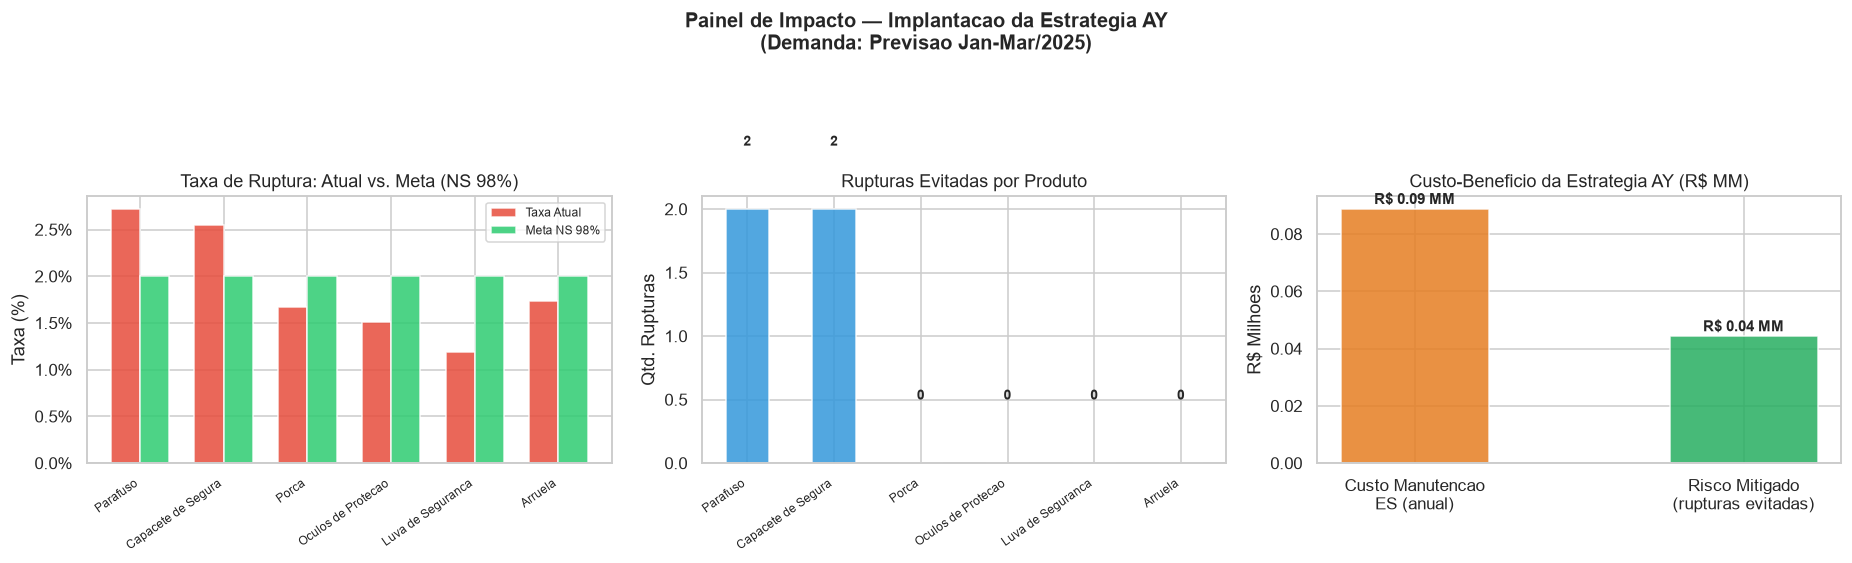

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
labels_imp = [p[:18] for p in impacto['produto']]
x = np.arange(len(impacto))
w = 0.35

# 1. Taxa de ruptura: atual vs. alvo
axes[0].bar(x - w/2, impacto['taxa_ruptura_atual'] * 100, w,
            label='Taxa Atual', color='#e74c3c', alpha=0.85)
axes[0].bar(x + w/2, impacto['taxa_ruptura_alvo'] * 100, w,
            label='Meta NS 98%', color='#2ecc71', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels_imp, rotation=35, ha='right', fontsize=8)
axes[0].set_title('Taxa de Ruptura: Atual vs. Meta (NS 98%)')
axes[0].set_ylabel('Taxa (%)')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.1f}%'))
axes[0].legend(fontsize=8)

# 2. Rupturas evitadas por produto
axes[1].bar(x, impacto['rupturas_evitadas'], color='#3498db', alpha=0.85, width=0.5)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels_imp, rotation=35, ha='right', fontsize=8)
axes[1].set_title('Rupturas Evitadas por Produto')
axes[1].set_ylabel('Qtd. Rupturas')
for i, v in enumerate(impacto['rupturas_evitadas']):
    axes[1].text(i, v + 0.5, f'{v:.0f}', ha='center', fontsize=9, fontweight='bold')

# 3. Custo de manutencao vs. risco mitigado
cats   = ['Custo Manutencao\nES (anual)', 'Risco Mitigado\n(rupturas evitadas)']
vals   = [total_custo_manut_es / 1e6, total_risco_mitigado / 1e6]
colors = ['#e67e22', '#27ae60']
bars3  = axes[2].bar(cats, vals, color=colors, alpha=0.85, width=0.45)
axes[2].set_title('Custo-Beneficio da Estrategia AY (R$ MM)')
axes[2].set_ylabel('R$ Milhoes')
for bar, v in zip(bars3, vals):
    axes[2].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + max(vals) * 0.02,
                 f'R$ {v:.2f} MM', ha='center', fontsize=10, fontweight='bold')

plt.suptitle('Painel de Impacto — Implantacao da Estrategia AY\n'
             '(Demanda: Previsao Jan-Mar/2025)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [21]:
# Colunas derivadas para o painel
params['cobertura_recomendada_dias'] = (
    params['lead_time_medio']
    + params['es_sugerido'] / params['demanda_media_diaria'].replace(0, np.nan)
).round(1)

params['situacao_cobertura'] = params.apply(
    lambda r: 'ADEQUADO'
    if r['cobertura_atual_dias'] >= r['cobertura_recomendada_dias']
    else 'CRITICO',
    axis=1,
)

painel_final = (
    params[['id_produto', 'produto', 'categoria',
             'demanda_media_diaria', 'lead_time_medio',
             'es_sugerido', 'pp_atual', 'pp_otimizado',
             'eoq', 'cobertura_atual_dias', 'cobertura_recomendada_dias',
             'situacao_cobertura', 'custo_manut_es']]
    .merge(
        impacto[['id_produto', 'taxa_ruptura_atual',
                 'rupturas_evitadas', 'valor_risco_mitigado']],
        on='id_produto', how='left',
    )
    .drop(columns='id_produto')
)

print('=== PAINEL CONSOLIDADO — INDICADORES AY (Demanda Prevista) ===')
display(
    painel_final.round({'demanda_media_diaria': 1, 'lead_time_medio': 1,
                         'taxa_ruptura_atual': 3})
)

painel_final.to_csv('data/otimizacao_estoque_ay.csv', index=False)
print(f'\nArquivo salvo: data/otimizacao_estoque_ay.csv ({len(painel_final)} itens AY)')


=== PAINEL CONSOLIDADO — INDICADORES AY (Demanda Prevista) ===


,produto,categoria,demanda_media_diaria,lead_time_medio,es_sugerido,pp_atual,pp_otimizado,eoq,cobertura_atual_dias,cobertura_recomendada_dias,situacao_cobertura,custo_manut_es,taxa_ruptura_atual,rupturas_evitadas,valor_risco_mitigado
0,Parafuso,Fixadores,1186.0,14.0,36535.0,6000,53182.0,6645.0,365.0,44.8,ADEQUADO,35331.0,0.027,2.0,27465.0
1,Capacete de Seguranca,EPI,105.9,13.3,3260.0,600,4664.0,796.0,365.0,44.0,ADEQUADO,19636.0,0.025,2.0,16792.0
2,Porca,Fixadores,1046.7,13.0,33214.0,6000,46824.0,9935.0,365.0,44.7,ADEQUADO,12679.0,0.017,0.0,0.0
3,Oculos de Protecao,EPI,97.4,13.5,3125.0,600,4440.0,1043.0,365.0,45.6,ADEQUADO,10072.0,0.015,0.0,0.0
4,Luva de Seguranca,EPI,89.4,14.4,3072.0,600,4361.0,1109.0,365.0,48.8,ADEQUADO,8042.0,0.012,0.0,0.0
5,Arruela,Fixadores,994.2,7.5,15146.0,6000,22581.0,13578.0,365.0,22.7,ADEQUADO,2941.0,0.017,0.0,0.0



Arquivo salvo: data/otimizacao_estoque_ay.csv (6 itens AY)


## Resumo Executivo — Estratégia AY

---

### Escopo da Análise

| Dimensão | Resultado |
|---|---|
| Itens analisados | **6 produtos** — quadrante AY da Matriz ABC-XYZ |
| Valor financeiro coberto | **R$ 12,6 MM (69,2% do portfólio total)** |
| Demanda de referência | **Previsão Jan-Mar/2025** (Walk-Forward Validation) |
| Nível de serviço adotado | **98%** → Z = 2,054 |
| Taxa de posse | 20% a.a. · Custo de emissão: R$ 50/pedido |

---

### Diagnóstico de Cobertura — Situação ADEQUADA em 100% dos Itens

O painel consolidado mostrou que **todos os 6 itens AY estão com cobertura ADEQUADA**: a cobertura atual (365 dias, no teto) está muito acima da cobertura recomendada (LT + ES/D prevista), que varia de 22,7 a 48,8 dias. O problema desses itens hoje é **excesso de estoque**, não risco de falta — com a ressalva de que o `estoque_disponivel` da base está acima do `estoque_maximo` cadastrado e precisa ser validado.

---

### Achados por Indicador

**Estoque de Segurança (ES)**
- A fórmula captura dois vetores de incerteza simultaneamente: variabilidade de demanda (histórica) e variabilidade de lead time.
- Com NS 98%, o ES total é de **94.352 un.** (R$ 443,5 mil imobilizados, **R$ 88,7 mil/ano** de custo de manutenção), equivalente a 15–34 dias de demanda por item. Com NS 95% seriam 75.567 un. (R$ 71,0 mil/ano) e com NS 90%, 58.876 un. (R$ 55,3 mil/ano).
- A previsão Jan-Mar/2025 está **acima** da média histórica nos 6 produtos (de +2% em Luva de Segurança a +36% em Parafuso), o que eleva o ES em relação a um cálculo feito com a demanda histórica.

**Ponto de Pedido (PP)**
- **100% dos itens com PP subestimado** — o `estoque_minimo` atual (600 ou 6.000 un.) fica de 3,8x a 8,9x abaixo do PP otimizado; o gap médio é de 19.375 un.
- Atualizar os PPs no ERP é a correção estrutural mais importante, mas **sem efeito imediato**: o estoque atual está de 13x a 32x acima do PP otimizado, então nenhum pedido seria disparado agora.

**Lote Econômico de Compra (EOQ)**
- Pedidos anuais caem de **807 para 239 (−70%)** com a adoção do EOQ.
- Menos pedidos, lotes maiores (de 2,3x a 4,9x o lote médio atual): redução no custo administrativo de compras.

**Taxa de Ruptura**
- Taxa média atual dos itens AY: **1,9%** — já dentro da meta de NS 98% (**2,0%**).
- Apenas **Parafuso (2,7%)** e **Capacete de Segurança (2,5%)** estão acima da meta; são os únicos com rupturas evitadas na projeção (4 de 38 rupturas históricas, **R$ 44,3 mil** de risco mitigado).

**Custo-Benefício**
- Manter o ES com NS 98% custa **R$ 88,7 mil/ano** e mitiga **R$ 44,3 mil** em risco de ruptura — retorno líquido de **−R$ 44,4 mil** e ROI de **0,5x**.
- O risco mitigado foi apurado sobre os 36 meses de histórico, enquanto o custo é anual — a relação real é ainda menos favorável.
- Pelo critério adotado (valor dos pedidos com ruptura), **aplicar NS 98% de forma uniforme aos 6 itens não se paga**.

---

### Plano de Ação Prioritário

| Prioridade | Ação | Impacto |
|:---:|---|---|
| 🔴 1 | Validar o `estoque_disponivel` dos 6 itens e suspender novas compras enquanto a cobertura estiver acima da recomendada | Evita ampliar o excesso de estoque |
| 🔴 2 | Atualizar PP no ERP com base nos valores otimizados | Corrige o parâmetro que hoje dispararia a compra tarde demais |
| 🟡 3 | Diferenciar o nível de serviço: NS 98% apenas para Parafuso e Capacete; avaliar NS 90–95% para os demais | Reduz o custo de manutenção do ES onde a ruptura já está abaixo da meta |
| 🟡 4 | Parametrizar lotes EOQ no sistema de compras | Redução de ~70% nos pedidos emitidos |
| 🟡 5 | Monitorar mensalmente cobertura vs. cobertura recomendada | Sinalização antecipada de rupturas e de excesso |